# 2. Are automatic masks as good as expert masks?

The same radiomics features were computed twice for every patient: from the expert mask (this is the feature table of the radiomics project) and from the U-Net mask of notebook 1. Here I compare what they do to

1. **grade prediction** (LGG vs HGG, 369 patients), and
2. **survival prediction** (236 HGG patients with known survival).

All evaluation uses the same 3 folds as the U-Net training, so a patient in a test fold was never seen by the segmentation model or by the grade/survival model.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import RocCurveDisplay

sys.path.insert(0, "../src")
import modeling as M  # copied from the radiomics project

warnings.filterwarnings("ignore", category=UserWarning)
FIGURES = Path("../results/figures")

expert = M.load_features("../../Glioma_Grade_Radiomics/data/features.csv").set_index("case")
auto = M.load_features("../data/features_auto.csv").set_index("case").loc[expert.index]
folds = pd.Series(json.loads(Path("../data/folds.json").read_text())).loc[expert.index]
y = expert["y"]  # 1 = LGG

shape = M.feature_groups(expert.reset_index())["shape"]
volumes = M.feature_groups(expert.reset_index())["volumes (6)"]
print(len(expert), "patients |", len(shape), "shape features |", (y == 1).sum(), "LGG")

369 patients | 48 shape features | 76 LGG


## How much do the features change?

First a simple check: for each shape feature, the Spearman correlation between its value from the expert mask and from the U-Net mask, across patients.

In [2]:
agreement = pd.Series({c: expert[c].corr(auto[c], method="spearman") for c in shape}).dropna().sort_values()
region = agreement.index.str.extract(r"^(WT|TC|ET|vol)")[0].fillna("other").values
print(agreement.groupby(region).median().round(2).to_string())
print("\nleast stable:")
print(agreement.head(6).round(2).to_string())

ET     0.54
TC     0.57
WT     0.64
vol    0.78

least stable:
WT_shape_Maximum3DDiameter         -0.02
WT_shape_Maximum2DDiameterColumn   -0.00
ET_shape_Maximum3DDiameter          0.07
TC_shape_Maximum3DDiameter          0.09
WT_shape_Maximum2DDiameterRow       0.10
TC_shape_Maximum2DDiameterColumn    0.11


Volume features agree best (median ρ ≈ 0.78). The **maximum-diameter features don't agree at all** (ρ ≈ 0). A quick check on every 4th patient showed why: the U-Net masks have a median of 22 separate connected pieces (expert masks: 8), but the largest piece holds 99% of the volume. The extra pieces are tiny, yet one of them far from the tumor is enough to make the "maximum diameter" huge. Keeping only the largest connected region of each U-Net mask would probably fix most of this — something to try next.

## Grade prediction

Same model as the selected one in the radiomics project: LASSO logistic regression on the 48 shape features. Three scenarios:

1. **expert → expert**: trained and tested on features from expert masks (the radiomics project's setting)
2. **auto → auto**: trained and tested on features from U-Net masks
3. **expert → auto**: trained on expert masks, tested on U-Net masks — what happens if a model built on annotated data is used on new patients that only have automatic masks

Predictions are collected out-of-fold over the 3 folds, and the AUC has a 95% bootstrap interval.

In [3]:
lasso = M.make_models()["LASSO logistic regression"]


def out_of_fold(train_on, test_on):
    probability = pd.Series(index=y.index, dtype=float)
    for k in range(3):
        train, test = folds != k, folds == k
        model = clone(lasso).fit(train_on.loc[train, shape], y[train])
        probability[test] = model.predict_proba(test_on.loc[test, shape])[:, 1]
    return probability


scenarios = {"expert → expert": (expert, expert), "auto → auto": (auto, auto), "expert → auto": (expert, auto)}
grade_prob = {name: out_of_fold(*data) for name, data in scenarios.items()}

grade_results = pd.DataFrame(
    [M.bootstrap_auc(y, p) for p in grade_prob.values()],
    index=grade_prob.keys(), columns=["ROC AUC", "95% CI low", "95% CI high"],
).round(3)
grade_results.to_csv("../results/grade_auc.csv")
grade_results

,ROC AUC,95% CI low,95% CI high
expert → expert,0.951,0.915,0.982
auto → auto,0.920,0.873,0.962
expert → auto,0.846,0.787,0.900


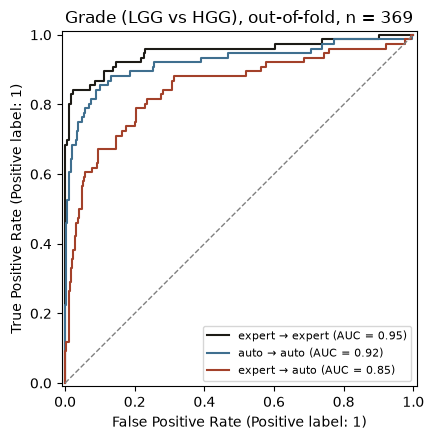

In [4]:
fig, ax = plt.subplots(figsize=(5, 4.5))
for (name, p), color in zip(grade_prob.items(), ["#1d1b16", "#3f6f8f", "#a3412a"]):
    RocCurveDisplay.from_predictions(y, p, ax=ax, name=name, curve_kwargs={"color": color})
ax.plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
ax.set_title("Grade (LGG vs HGG), out-of-fold, n = 369")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "grade_roc.png", dpi=130, bbox_inches="tight")
plt.show()

In [5]:
# where does "expert -> auto" lose? compare the predicted LGG probability per group of patients
no_enhancement = expert["ET_present"] == 0
groups = pd.Series(np.select([no_enhancement, y == 1], ["LGG, no enhancement", "LGG, enhancing"], "HGG"),
                   index=y.index)
pd.DataFrame({name: p.groupby(groups).median() for name, p in grade_prob.items()}).round(2)

,expert → expert,auto → auto,expert → auto
HGG,0.09,0.21,0.11
"LGG, enhancing",0.95,0.84,0.80
"LGG, no enhancement",0.99,0.92,0.61


- With U-Net masks for both training and testing, the grade model loses a little (AUC 0.95 → 0.92).
- **A model trained on expert masks and applied to U-Net masks loses much more (0.85).** The table shows where: for LGG without enhancement the predicted LGG probability falls from 0.99 to 0.61. The expert-trained model learned "no enhancement → LGG", and the U-Net adds small enhancing regions to exactly these tumors (notebook 1).
- So the masks used for training should come from the same source as the masks the model will see later. Training on U-Net masks lets the model adapt to the U-Net's own mistakes.

## Survival prediction

BraTS 2020 has overall survival for 236 patients, all HGG. Every survival time is a death except one patient recorded as alive after 361 days, who is treated as censored. Besides the images, age and extent of resection (gross total / subtotal / unknown for 107 patients) are available.

Models (Cox, small ridge penalty, features standardized inside each training fold):

1. age + resection — the clinical baseline
2. \+ the 6 volume features, from expert or U-Net masks
3. \+ the 48 shape features, from expert or U-Net masks

Same 3 folds again; C-index on the pooled out-of-fold risk scores, with a 95% bootstrap interval.

In [6]:
from lifelines import CoxPHFitter
from lifelines.utils import concordance_index

survival = pd.read_csv("../../Glioma_Grade_Radiomics/data/brats2020/survival_info.csv").set_index("Brats20ID")
survival["event"] = pd.to_numeric(survival["Survival_days"], errors="coerce").notna().astype(int)
survival["time"] = survival["Survival_days"].astype(str).str.extract(r"(\d+)")[0].astype(float)
survival["resection_GTR"] = (survival["Extent_of_Resection"] == "GTR").astype(int)
survival["resection_STR"] = (survival["Extent_of_Resection"] == "STR").astype(int)
clinical = ["Age", "resection_GTR", "resection_STR"]

print(survival["event"].value_counts().to_dict(), "| median survival", survival["time"].median(), "days")
survival[["Age", "time"]].describe().round(1)

{1: 235, 0: 1} | median survival 369.0 days


,Age,time
count,236.0,236.0
mean,61.2,445.5
std,11.9,355.2
min,19.0,5.0
25%,54.2,190.0
50%,61.5,369.0
75%,69.2,579.2
max,86.7,1767.0


Median survival is 369 days, about a year, as expected for high-grade glioma.

In [7]:
def cox_out_of_fold(features=None, columns=()):
    data = survival[["time", "event"] + clinical]
    if features is not None:
        data = data.join(features[list(columns)])
    risk = pd.Series(index=data.index, dtype=float)
    for k in range(3):
        test = folds.loc[data.index] == k
        train_data, test_data = data[~test].copy(), data[test].copy()
        # drop features that are constant in this training fold (e.g. "ET present": every HGG enhances)
        used = [c for c in data.columns[2:] if train_data[c].std() > 0]
        mean, std = train_data[used].mean(), train_data[used].std()
        train_data[used] = (train_data[used] - mean) / std
        test_data[used] = (test_data[used] - mean) / std
        cox = CoxPHFitter(penalizer=0.1).fit(train_data[["time", "event"] + used], "time", "event")
        risk[test] = cox.predict_partial_hazard(test_data[used])
    return data, risk


def bootstrap_c_index(data, risk, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    c = concordance_index(data["time"], -risk, data["event"])
    values = []
    for _ in range(n_boot):
        i = rng.integers(0, len(data), len(data))
        values.append(concordance_index(data["time"].values[i], -risk.values[i], data["event"].values[i]))
    return c, *np.percentile(values, [2.5, 97.5])


survival_models = {
    "age + resection": (None, ()),
    "+ volumes, expert masks": (expert, volumes),
    "+ volumes, U-Net masks": (auto, volumes),
    "+ shape, expert masks": (expert, shape),
    "+ shape, U-Net masks": (auto, shape),
}
survival_results = pd.DataFrame(
    [bootstrap_c_index(*cox_out_of_fold(*args)) for args in survival_models.values()],
    index=survival_models.keys(), columns=["C-index", "95% CI low", "95% CI high"],
).round(3)
survival_results.to_csv("../results/survival_c_index.csv")
survival_results

,C-index,95% CI low,95% CI high
age + resection,0.619,0.579,0.660
"+ volumes, expert masks",0.628,0.588,0.668
"+ volumes, U-Net masks",0.614,0.573,0.655
"+ shape, expert masks",0.634,0.593,0.673
"+ shape, U-Net masks",0.608,0.565,0.651


- Age and resection alone give a C-index of 0.62.
- Tumor shape from expert masks adds about 0.01–0.02, and from U-Net masks nothing. All intervals overlap heavily: with 236 patients none of these differences is distinguishable from noise.
- Imaging, at least in the form of tumor volume and shape, adds little to survival prediction in this dataset, whichever masks are used.

## Conclusion

**Are automatic masks as good as expert masks?** It depends on the task and on how the model is trained.

| | expert masks | U-Net masks |
|---|---|---|
| Grade, ROC AUC (model trained on the same mask type) | 0.95 (0.92–0.98) | 0.92 (0.87–0.96) |
| Grade, model trained on expert masks | 0.95 | **0.85** (0.79–0.90) |
| Survival, C-index (age + resection + shape) | 0.63 (0.59–0.67) | 0.61 (0.57–0.65) |
| Survival, age + resection only | 0.62 | 0.62 |

1. **Whole-tumor masks from the U-Net are close to the expert ones** (median Dice 0.91), but the enhancing part of low-grade tumors is not: the U-Net adds small enhancing regions to 26 of 27 non-enhancing LGG.
2. **For grade, U-Net masks work almost as well if the model is also trained on U-Net masks.** A model trained on expert masks and applied to U-Net masks drops to AUC 0.85, because the "no enhancement → LGG" signal it relies on is exactly what the U-Net gets wrong.
3. **For survival, the mask type barely matters**, because tumor shape adds little to age in the first place.

**Limitations:** a 2D U-Net trained for only 10 epochs per fold; shape features only (texture features carry a strong scanner signal in BraTS, see the radiomics project); survival only for HGG and only 236 patients; and the source/grade confounding of BraTS described in the radiomics project applies here too.

**Next steps:** keep only the largest connected region of each U-Net mask, which should fix the maximum-diameter features; and train the U-Net with more LGG cases (or class weighting) to reduce false enhancement.